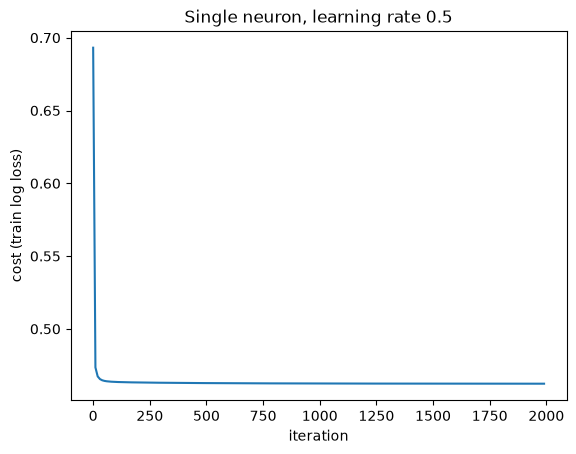

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

run = json.loads(Path("../results/neuron_dev.json").read_text())
costs = run["costs"]
iterations = [i * 10 for i in range(len(costs))]

plt.plot(iterations, costs)
plt.xlabel("iteration")
plt.ylabel("cost (train log loss)")
plt.title(f"Single neuron, learning rate {run['learning_rate']}")
plt.show()

In [2]:
print("cost at iteration 1000:", costs[100])
print("cost at iteration 1500:", costs[150])
print("cost at iteration 1990:", costs[-1])
print("drop over the last ~500 iterations:", costs[150] - costs[-1])

cost at iteration 1000: 0.4625019049433078
cost at iteration 1500: 0.46240409287930745
cost at iteration 1990: 0.4623640850054672
drop over the last ~500 iterations: 4.000787384023097e-05


## What the single neuron showed me

- My NumPy neuron (learning rate 0.5, 2000 steps, plain gradient descent) got dev ROC-AUC 0.7139. The sklearn baseline got 0.7143. PR-AUC, F1 and log loss match to the third decimal too, and the confusion matrix differs by one customer.
- The cost started at exactly 0.693 (log 2), because zero weights give everyone 0.5, and ended at 0.462 on train.
- The curve is basically flat by the end: the cost only fell 0.00004 over the last 500 steps. So running longer wouldn't change much.
- The tiny gap left is mostly because sklearn adds a bit of L2 regularisation by default and mine doesn't.
- So my forward pass, cost and gradients are right, and 0.714 is what one neuron can do on this data. The next question is whether a hidden layer can beat it.